In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv("AB_NYC_2019_cleaned.csv")
print("Shape:", df.shape)
df.head()

Shape: (45748, 11)


,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45748 entries, 0 to 45747
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             45748 non-null  object 
 1   neighbourhood                   45748 non-null  object 
 2   latitude                        45748 non-null  float64
 3   longitude                       45748 non-null  float64
 4   room_type                       45748 non-null  object 
 5   price                           45748 non-null  int64  
 6   minimum_nights                  45748 non-null  int64  
 7   number_of_reviews               45748 non-null  int64  
 8   reviews_per_month               45748 non-null  float64
 9   calculated_host_listings_count  45748 non-null  int64  
 10  availability_365                45748 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 3.8+ MB


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,45748.000000,45748.000000,45748.000000,45748.000000,45748.000000,45748.000000,45748.000000,45748.000000
mean,40.728464,-73.950802,122.544483,5.557401,24.014908,1.116854,6.688577,108.685188
std,0.055207,0.046519,71.950454,8.176296,45.347668,1.617559,31.223704,130.049442
min,40.499790,-74.244420,10.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,40.689298,-73.981992,65.000000,1.000000,1.000000,0.050000,1.000000,0.000000
50%,40.721890,-73.954500,100.000000,2.000000,6.000000,0.390000,1.000000,38.000000
75%,40.763240,-73.934400,160.000000,5.000000,25.000000,1.640000,2.000000,215.000000
max,40.913060,-73.712990,355.000000,30.000000,629.000000,58.500000,327.000000,365.000000


In [4]:
# Missing values (should all be 0)
print(df.isnull().sum())

# Numerical vs categorical columns
print("Numerical:", df.select_dtypes(include="number").columns.tolist())
print("Categorical:", df.select_dtypes(exclude="number").columns.tolist())

neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64
Numerical: ['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Categorical: ['neighbourhood_group', 'neighbourhood', 'room_type']


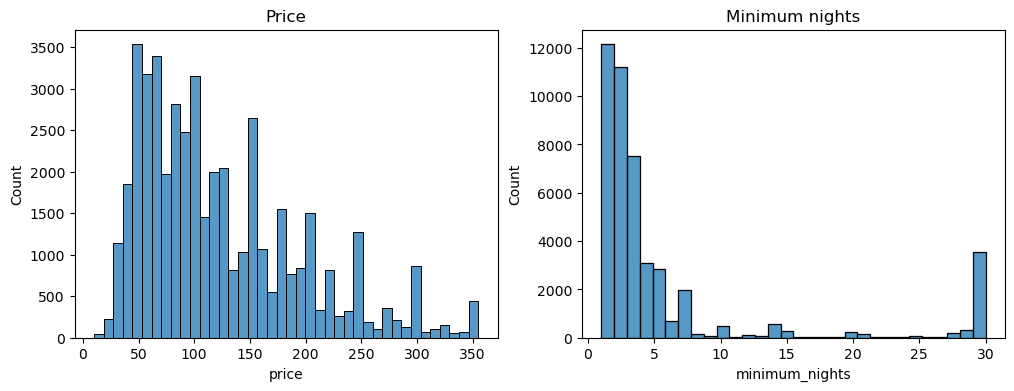

Max price: 355
Max minimum nights: 30


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=40, ax=axes[0]);          axes[0].set_title("Price")
sns.histplot(df["minimum_nights"], bins=30, ax=axes[1]); axes[1].set_title("Minimum nights")
plt.show()

print("Max price:", df["price"].max())
print("Max minimum nights:", df["minimum_nights"].max())

In [6]:
# neighbourhood has 219 unique values -> too many columns (curse of dimensionality), so drop it
print("neighbourhood unique values:", df["neighbourhood"].nunique())
df = df.drop(columns=["neighbourhood"])

neighbourhood unique values: 219


In [7]:
# One-hot encoding; drop_first=True avoids the dummy variable trap
df = pd.get_dummies(df, columns=["neighbourhood_group", "room_type"], drop_first=True)
print(df.columns.tolist())
df.head()

['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,True,False,False,False,True,False
1,40.75362,-73.98377,225,1,45,0.38,2,355,False,True,False,False,False,False
2,40.80902,-73.94190,150,3,0,0.00,1,365,False,True,False,False,True,False
3,40.68514,-73.95976,89,1,270,4.64,1,194,True,False,False,False,False,False
4,40.79851,-73.94399,80,10,9,0.10,1,0,False,True,False,False,False,False


In [8]:
X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])


Training rows: 36598
Testing rows : 9150


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R-squared : {r2:.3f}")
print(f"MAE       : ${mae:.2f}")
print(f"MSE       : {mse:.2f}")
print(f"RMSE      : ${rmse:.2f}")


R-squared : 0.487
MAE       : $38.32
MSE       : 2760.62
RMSE      : $52.54


In [10]:
# Which features affect price the most?
coefficients = pd.Series(model.coef_, index=X.columns).sort_values()
print(coefficients.round(2))

longitude                           -297.51
room_type_Shared room               -104.58
neighbourhood_group_Staten Island    -82.93
room_type_Private room               -79.12
latitude                             -76.23
neighbourhood_group_Brooklyn          -8.21
reviews_per_month                     -1.06
minimum_nights                        -1.04
number_of_reviews                     -0.07
availability_365                       0.07
calculated_host_listings_count         0.14
neighbourhood_group_Queens             5.67
neighbourhood_group_Manhattan         23.45
dtype: float64


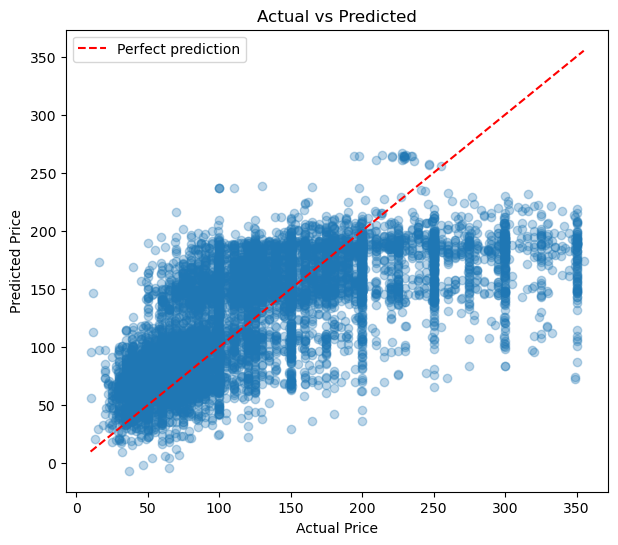

In [11]:
# Actual vs Predicted with the 45-degree line
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="Perfect prediction")
plt.xlabel("Actual Price"); plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted"); plt.legend()
plt.show()


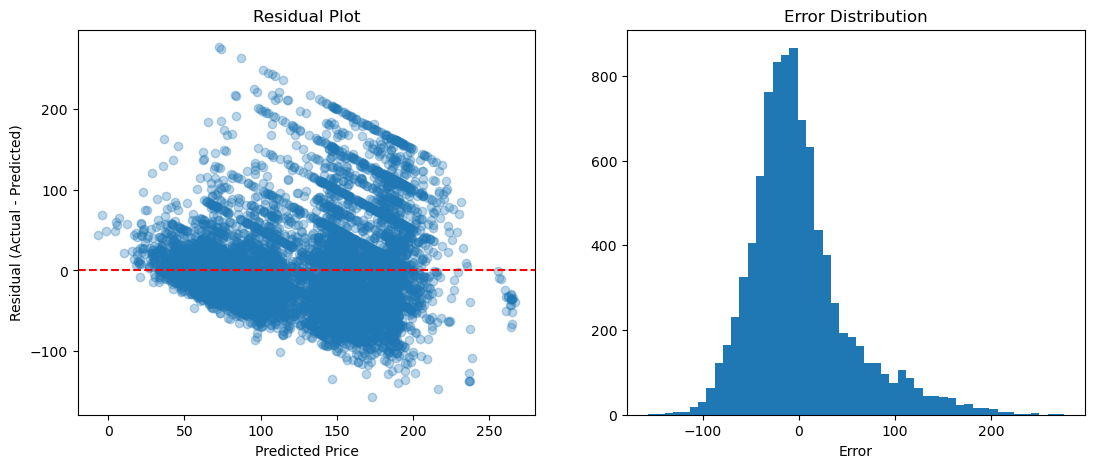

In [12]:
# Residual plot and error histogram
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_pred, residuals, alpha=0.3)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Price"); axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("Residual Plot")

axes[1].hist(residuals, bins=50)
axes[1].set_xlabel("Error"); axes[1].set_title("Error Distribution")
plt.show()

In [14]:
# Cheap vs medium vs expensive listings
results = pd.DataFrame({"actual": y_test, "predicted": y_pred})
results["abs_error"] = (results["actual"] - results["predicted"]).abs()
results["pct_error"] = results["abs_error"] / results["actual"] * 100
results["bias"] = results["predicted"] - results["actual"]
results["group"] = pd.qcut(results["actual"], 3, labels=["Cheap", "Medium", "Expensive"])

print(results.groupby("group")[["abs_error", "pct_error", "bias"]].mean().round(2))

           abs_error  pct_error   bias
group                                 
Cheap          26.37      52.75  22.11
Medium         33.96      33.14  19.99
Expensive      54.68      23.34 -45.19


C:\Users\POOJA PATIL A B\AppData\Local\Temp\ipykernel_34936\1388607522.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(results.groupby("group")[["abs_error", "pct_error", "bias"]].mean().round(2))
